# Projeto Integrador, Ciência de Dados Aplicada a Situações de Mercado

## Calculadora de Estimativa de Horas de Implantação de ERP (SAP Business One)

**2ª Etapa, especificação e aplicação do modelo de aprendizado de máquina**

Este notebook treina e avalia o modelo que estima o total de horas de implantação a partir das características do cliente. O código de apoio está em `src/modelo.py`, e os dados são lidos do Data Warehouse (`data/calculadora.db`), carregado pelo processo ETL (`src/etl.py`).

**Abordagem escolhida**

Aprendizado **supervisionado**, tarefa de **regressão**. Cada projeto da base possui as características do cliente (entradas) e o total de horas já conhecido (rótulo), e o valor a prever é numérico e contínuo (Ferreira, 2024).

## 1. Preparação do ambiente

In [1]:
import sys, subprocess
from pathlib import Path

# Localiza a raiz do repositório (funciona localmente e no Google Colab)
RAIZ = Path.cwd().parent if (Path.cwd().parent / "src").exists() else Path.cwd()
if not (RAIZ / "src").exists():
    subprocess.run(["git", "clone", "https://github.com/walmarina/calculadora_implantacao_sap_v3"], check=True)
    RAIZ = Path.cwd() / "calculadora_implantacao_sap_v3"
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import modelo as m

pd.set_option("display.width", 200)
plt.rcParams.update({
    "figure.figsize": (9, 5), "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#9a9893"

## 2. Carga dos dados a partir do Data Warehouse

Os dados vêm da view `vw_projetos_analitico`, que junta a tabela fato `dw_fato_projeto` às suas dimensões.

In [2]:
df = m.carregar_dados(RAIZ / "data" / "calculadora.db")
print(df.shape)
df.head()

(300, 17)


,id_projeto,data_proposta,ano,trimestre,tipo_ambiente,modalidade,porte,volume_notas_mensal,usa_van_bancaria,plano_contas_customizado,numero_usuarios,numero_filiais,qtd_addons,qtd_modulos,complexidade_importacao,notas_mensal,horas_totais_implantacao
0,PRJ1000,2025-12-23,2025,4,Compartilhado,Cloud,Grande (acima de 50 usuários),8.001 a 15.000,Não,Não,54,1,4,4,3,9815,273.4
1,PRJ1001,2023-08-17,2023,3,Compartilhado,On Premise,Pequeno (até 20 usuários),8.001 a 15.000,Não,Sim,17,5,1,3,7,14149,264.4
2,PRJ1002,2023-02-03,2023,1,Compartilhado,Cloud,Grande (acima de 50 usuários),8.001 a 15.000,Não,Não,74,3,4,2,10,12842,395.1
3,PRJ1003,2025-03-28,2025,1,Dedicado,Cloud,Grande (acima de 50 usuários),1.001 a 4.000,Não,Não,63,4,6,6,5,3790,443.2
4,PRJ1004,2024-04-11,2024,2,Dedicado,On Premise,Médio (21 a 50 usuários),8.001 a 15.000,Sim,Sim,23,3,0,5,8,12516,301.8


## 3. Seleção de características

Seguindo Ferreira (2024), foram mantidas apenas as variáveis com valor preditivo e disponíveis no momento da proposta comercial. Foram excluídos identificadores, colunas redundantes e qualquer coluna calculada a partir do próprio rótulo.

As horas por fase da metodologia SAP AIP, criadas na 1ª etapa, **não entram no modelo**, porque são uma porcentagem fixa do total de horas. Usá-las como entrada seria vazamento de dados (*data leakage*), e o modelo apresentaria métricas artificialmente perfeitas.

In [3]:
print("Entradas do modelo:", m.ENTRADAS + ["usuarios_x_filiais (criada)"])
pd.Series(m.EXCLUIDAS, name="motivo da exclusão").to_frame()

Entradas do modelo: ['numero_usuarios', 'numero_filiais', 'qtd_addons', 'qtd_modulos', 'complexidade_importacao', 'notas_mensal', 'tipo_ambiente', 'modalidade', 'usa_van_bancaria', 'plano_contas_customizado', 'usuarios_x_filiais (criada)']


,motivo da exclusão
id_projeto,"identificador, não ajuda a generalizar"
data_proposta,"data da proposta, sem relação causal com o esf..."
ano,derivada da data da proposta
trimestre,derivada da data da proposta
porte,derivada de numero_usuarios (redundância)
volume_notas_mensal,faixa derivada de notas_mensal (redundância)


A correlação de Pearson com o rótulo (método de filtro) confirma o que a 1ª etapa já mostrava.

In [4]:
df[m.NUMERICAS + [m.ALVO]].corr()[m.ALVO].drop(m.ALVO).sort_values(ascending=False).round(2)

numero_usuarios            0.63
numero_filiais             0.60
qtd_addons                 0.31
qtd_modulos                0.27
complexidade_importacao    0.05
notas_mensal               0.04
Name: horas_totais_implantacao, dtype: float64

## 4. Extração de característica e pré-processamento

**Extração.** Foi criada a variável `usuarios_x_filiais`, produto entre usuários e filiais. Ela representa o fato de que cada filial adicional multiplica o esforço de configuração para todos os usuários.

**Pré-processamento.** As variáveis categóricas (`tipo_ambiente`, `modalidade`, `usa_van_bancaria`, `plano_contas_customizado`) passam por *One-Hot Encoding* e as numéricas por padronização (`StandardScaler`), para que nenhuma variável domine o modelo apenas pela escala. Tudo fica dentro de um `Pipeline`, que aplica as mesmas transformações no treino, no teste e na calculadora.

In [5]:
m.modelos_candidatos()["Regressão Linear"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('interacao', ...), ('preprocessamento', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function adi...x7f0b1a84c900>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=No

## 5. Treino e comparação de modelos

A base foi dividida em 80% para treino (240 projetos) e 20% para teste (60 projetos). Cada modelo foi avaliado com **validação cruzada 5-fold** na base de treino, e o escolhido é o de menor RMSE médio na validação cruzada. O conjunto de teste fica reservado para a avaliação final.

| Modelo | Papel na comparação |
|---|---|
| Regressão Linear (sem interação) | referência mais simples |
| Regressão Linear | com a variável criada `usuarios_x_filiais` |
| Ridge (L2) | regularização que reduz os coeficientes |
| Lasso (L1) | regularização que pode zerar coeficientes (seleção embutida) |
| Random Forest | conjunto de árvores, capta relações não lineares |

In [6]:
resultado = m.treinar_e_avaliar(df)
comparacao = resultado["comparacao"]
comparacao

,modelo,cv_MAE,cv_RMSE,cv_RMSE_desvio,cv_R2,treino_RMSE,teste_MAE,teste_MSE,teste_RMSE,teste_R2
0,Regressão Linear (sem interação),27.44,34.74,1.68,0.8653,32.64,24.72,981.68,31.33,0.8835
1,Regressão Linear,25.00,31.11,1.51,0.8917,29.57,23.84,887.51,29.79,0.8947
2,Ridge (L2),25.02,31.01,1.65,0.8929,29.61,23.75,879.85,29.66,0.8956
3,Lasso (L1),24.97,30.96,1.50,0.8932,29.60,23.87,888.26,29.80,0.8946
4,Random Forest,31.89,40.01,5.08,0.8260,22.11,30.39,1429.10,37.80,0.8304


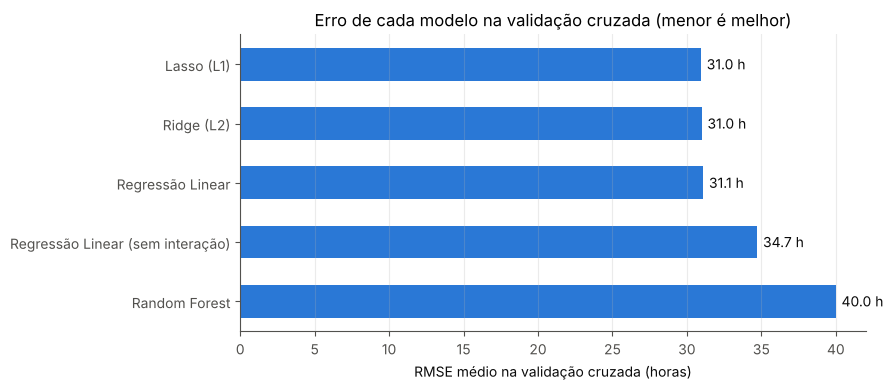

In [7]:
ordem = comparacao.sort_values("cv_RMSE", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
barras = ax.barh(ordem["modelo"], ordem["cv_RMSE"], color=AZUL, height=0.55)
ax.bar_label(barras, fmt="%.1f h", padding=4, color="#0b0b0b")
ax.set_xlabel("RMSE médio na validação cruzada (horas)")
ax.set_title("Erro de cada modelo na validação cruzada (menor é melhor)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 6. Overfitting e regularização

A comparação entre o erro no treino e o erro no teste mostra o *overfitting* descrito por Ferreira (2024). A Random Forest tem o menor erro no treino, mas o maior no teste, sinal de que memorizou o ruído da base. Os modelos lineares mantêm erros de treino e teste próximos, ou seja, generalizam bem.

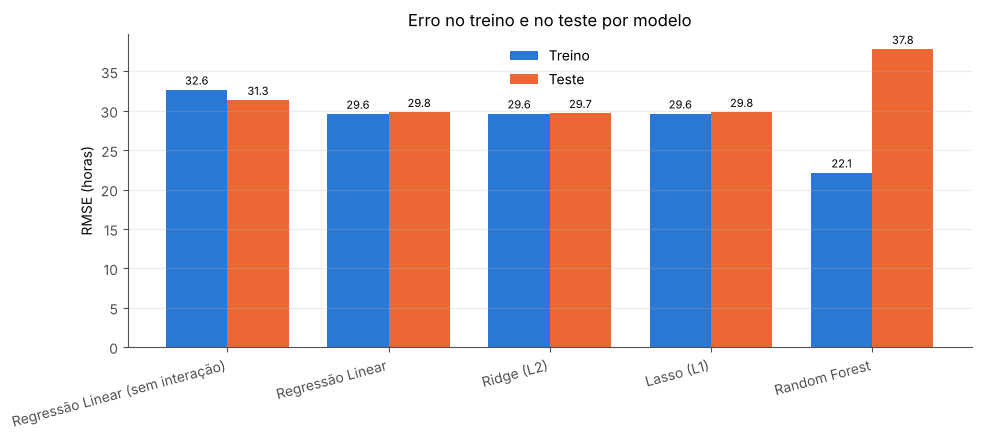

In [8]:
x = np.arange(len(comparacao)); largura = 0.38
fig, ax = plt.subplots(figsize=(10, 4.5))
b1 = ax.bar(x - largura/2, comparacao["treino_RMSE"], largura, color=AZUL, label="Treino")
b2 = ax.bar(x + largura/2, comparacao["teste_RMSE"], largura, color=LARANJA, label="Teste")
ax.bar_label(b1, fmt="%.1f", padding=2, fontsize=8); ax.bar_label(b2, fmt="%.1f", padding=2, fontsize=8)
ax.set_xticks(x, comparacao["modelo"], rotation=15, ha="right")
ax.set_ylabel("RMSE (horas)"); ax.set_title("Erro no treino e no teste por modelo")
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

O Lasso aplica a penalidade L1, que pode zerar coeficientes de variáveis sem valor preditivo. Na base, ele zerou o coeficiente da **modalidade (Cloud ou On Premise)**, indicando que essa variável não ajuda a estimar as horas.

In [9]:
print(f"alpha escolhido para o Lasso: {resultado['alpha_lasso']:.3f}")
print(f"alpha escolhido para o Ridge: {resultado['alpha_ridge']:.3f}")
resultado["coeficientes_lasso"].sort_values("coeficiente", key=abs, ascending=False)

alpha escolhido para o Lasso: 0.316
alpha escolhido para o Ridge: 5.623


,variavel,coeficiente
6,usuarios_x_filiais,40.064
0,numero_usuarios,33.663
2,qtd_addons,28.220
1,numero_filiais,25.547
3,qtd_modulos,17.134
10,plano_contas_customizado_Sim,16.883
7,tipo_ambiente_Dedicado,11.645
4,complexidade_importacao,11.280
5,notas_mensal,9.858
9,usa_van_bancaria_Sim,9.247


## 7. Avaliação final no conjunto de teste

Modelo escolhido pela validação cruzada: **Lasso (L1)**. As métricas abaixo foram calculadas nos 60 projetos de teste, que o modelo não viu durante a escolha.

In [10]:
nome = resultado["nome_melhor"]
linha = comparacao.set_index("modelo").loc[nome]
print("Modelo escolhido:", nome)
pd.Series({"MAE (horas)": linha.teste_MAE, "MSE": linha.teste_MSE,
           "RMSE (horas)": linha.teste_RMSE, "R²": linha.teste_R2}).to_frame("teste")

Modelo escolhido: Lasso (L1)


,teste
MAE (horas),23.8700
MSE,888.2600
RMSE (horas),29.8000
R²,0.8946


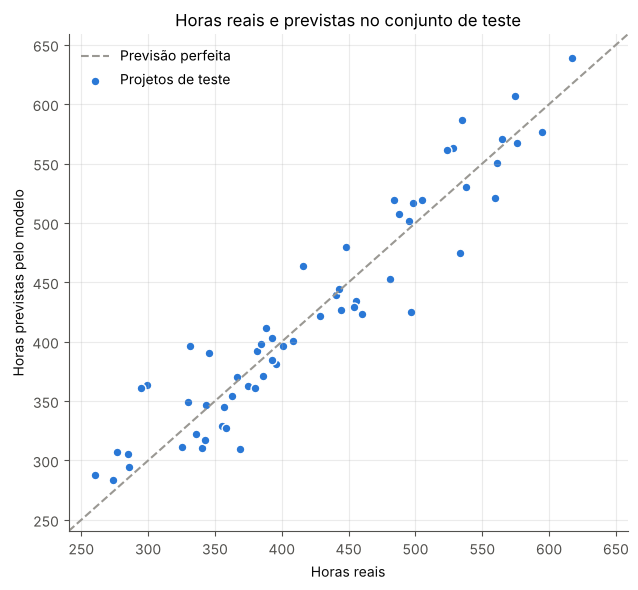

In [11]:
prev = resultado["previsoes_teste"]
fig, ax = plt.subplots(figsize=(6.5, 6))
limites = [prev[["horas_reais", "horas_previstas"]].min().min() - 20, prev[["horas_reais", "horas_previstas"]].max().max() + 20]
ax.plot(limites, limites, color=CINZA, linewidth=1.5, linestyle="--", label="Previsão perfeita")
ax.scatter(prev["horas_reais"], prev["horas_previstas"], s=40, color=AZUL, edgecolor="white", linewidth=1, label="Projetos de teste")
ax.set_xlim(limites); ax.set_ylim(limites)
ax.set_xlabel("Horas reais"); ax.set_ylabel("Horas previstas pelo modelo")
ax.set_title("Horas reais e previstas no conjunto de teste")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

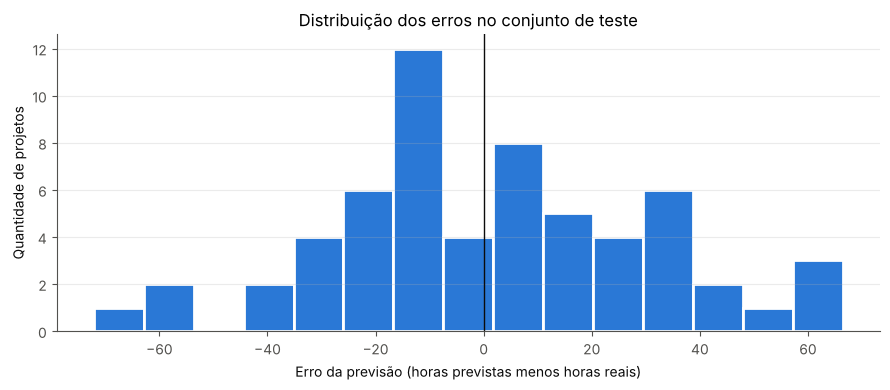

Faixa de 80% dos erros na validação cruzada (P10 a P90): (-40.4, 38.6)


In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(prev["erro"], bins=15, color=AZUL, edgecolor="white", linewidth=2)
ax.axvline(0, color="#0b0b0b", linewidth=1)
ax.set_xlabel("Erro da previsão (horas previstas menos horas reais)"); ax.set_ylabel("Quantidade de projetos")
ax.set_title("Distribuição dos erros no conjunto de teste")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print("Faixa de 80% dos erros na validação cruzada (P10 a P90):", resultado["faixa_residuos_p10_p90"])

**Leitura dos resultados.** O RMSE ficou próximo de 30 horas, que é exatamente o desvio padrão do ruído aleatório inserido na geração da base (1ª etapa). Isso indica que o modelo captou toda a parte explicável do esforço e que o erro restante é a variabilidade natural entre projetos de perfil semelhante. Por se tratar de dados sintéticos gerados por uma fórmula majoritariamente linear, é esperado que os modelos lineares superem a Random Forest. Com dados reais de projetos executados, a comparação precisa ser refeita.

## 8. Importância das variáveis (interpretabilidade)

A importância por permutação embaralha uma variável de cada vez e mede quanto o erro do modelo aumenta. Quanto maior o aumento, mais o modelo depende daquela variável. A técnica vale para qualquer modelo e reforça a transparência defendida por Ferreira (2024).

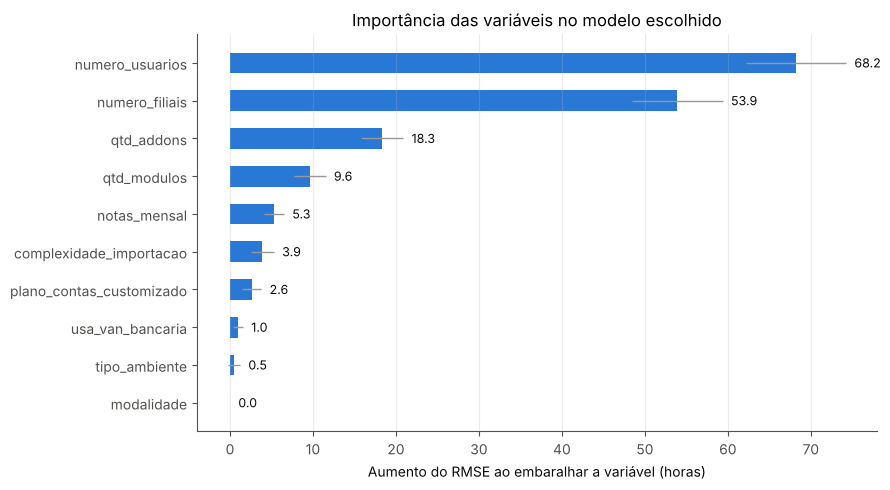

In [13]:
imp = resultado["importancia"].sort_values("aumento_RMSE")
fig, ax = plt.subplots(figsize=(9, 5))
barras = ax.barh(imp["variavel"], imp["aumento_RMSE"], xerr=imp["desvio"], color=AZUL, height=0.55,
                 error_kw={"ecolor": CINZA, "elinewidth": 1})
ax.bar_label(barras, fmt="%.1f", padding=6, color="#0b0b0b", fontsize=9)
ax.set_xlabel("Aumento do RMSE ao embaralhar a variável (horas)")
ax.set_title("Importância das variáveis no modelo escolhido")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 9. Uso do modelo na calculadora

O modelo final é retreinado com os 300 projetos e usado pela calculadora no Streamlit. A saída é o total de horas, uma faixa provável baseada nos erros da validação cruzada e o rateio pelas fases da metodologia SAP AIP.

In [14]:
novo_cliente = {
    "numero_usuarios": 25, "numero_filiais": 3, "qtd_addons": 2, "qtd_modulos": 5,
    "complexidade_importacao": 6, "notas_mensal": 3000, "tipo_ambiente": "Compartilhado",
    "modalidade": "Cloud", "usa_van_bancaria": "Sim", "plano_contas_customizado": "Não",
}
estimativa = m.estimar(resultado["modelo_final"], novo_cliente, resultado["faixa_residuos_p10_p90"])
print(f"Estimativa: {estimativa['horas']:.0f} horas (faixa provável de {estimativa['faixa_min']:.0f} a {estimativa['faixa_max']:.0f} horas)")
pd.DataFrame(estimativa["fases"], columns=["Fase SAP AIP", "Horas"])

Estimativa: 296 horas (faixa provável de 256 a 335 horas)


,Fase SAP AIP,Horas
0,Project Preparation,30.0
1,Business Blueprint,59.0
2,Project Realization,104.0
3,Final Preparation,74.0
4,Go-Live and Support,30.0


## 10. Monitoramento e evolução do modelo

* **Monitoramento.** A cada projeto concluído, registrar as horas realizadas e comparar com as previstas. Se o MAE dos últimos projetos ultrapassar o MAE de teste em mais de 20%, o modelo deve ser revisado.
* **Retreino.** Substituir progressivamente os dados sintéticos por projetos reais e repetir a validação cruzada a cada novo lote.
* **Vieses.** A base sintética reflete os pesos definidos pela equipe. As relações encontradas servem para validar o método, e não como verdade sobre implantações reais.

## Referência

FERREIRA, Poliana N. **Aprendizado de máquina**. São Paulo: Editora Senac São Paulo, 2024.